Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights
Objective: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.


In [1]:
import pandas as pd

df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [ ]:
df.isnull().sum()


Dataset: This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

Frequency Tables:

Generate a frequency table for the product category.
Which are the top 5 most listed product categories?
Visualizations:

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?



In [15]:
cat_number =  df['category'].value_counts()
cat_numberdf = cat_number.reset_index()
cat_numberdf.columns = ['Category', 'Frequency']

In [39]:
cat_numberdf_5 = cat_numberdf[:5]
# cat_numberdf

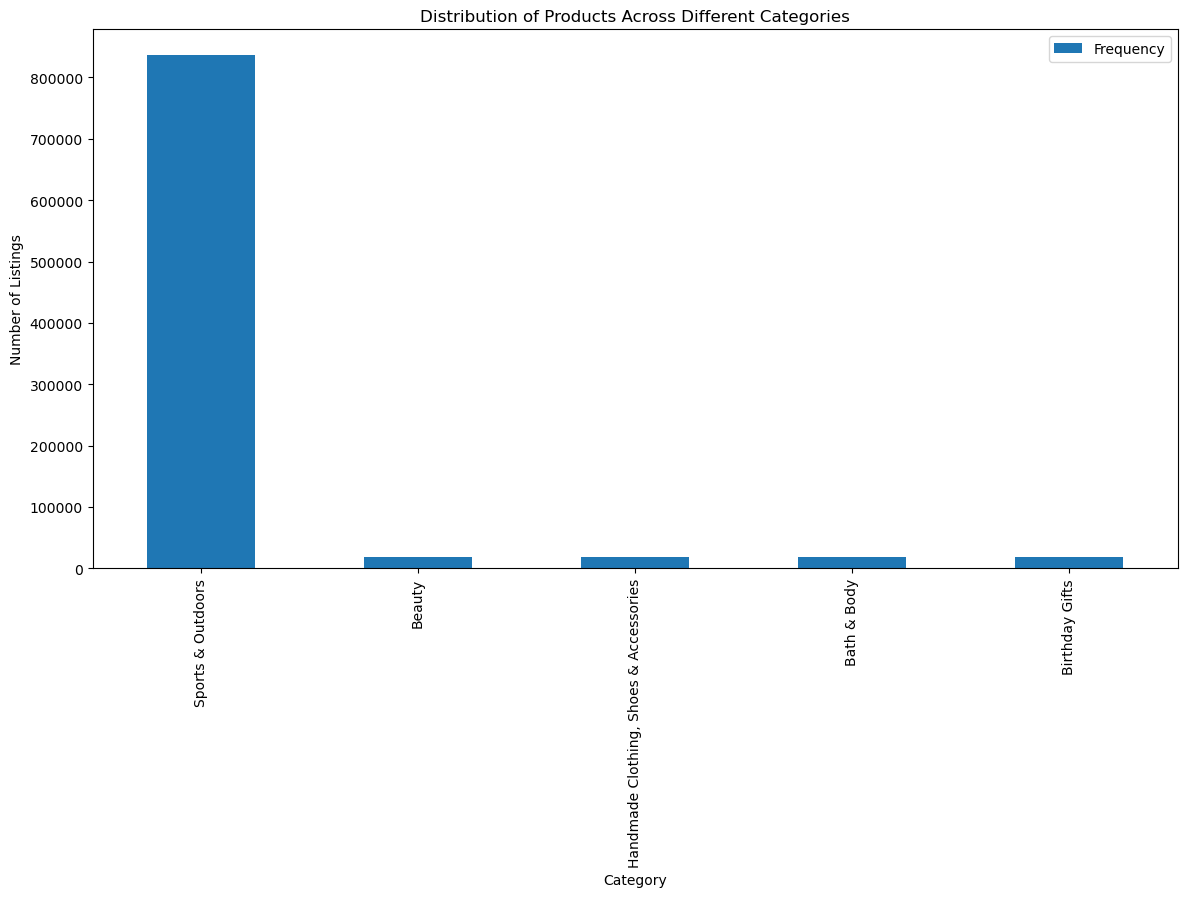

In [38]:
# Plot the distribution of products across all categories
cat_numberdf_5.plot(kind='bar', x='Category', y='Frequency', figsize=(14, 7), title='Distribution of Products Across Different Categories')
plt.xlabel('Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=90)
plt.show()


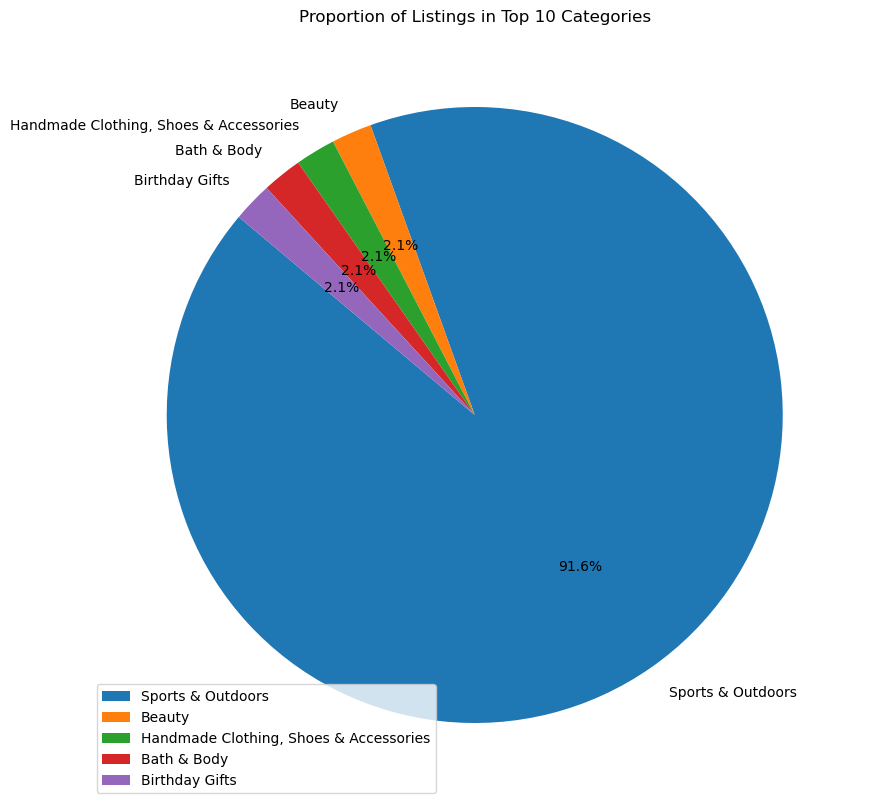

In [43]:
# Plot the proportions of the top 10 categories
cat_numberdf[:5].plot(kind='pie', y='Frequency', labels=cat_numberdf['Category'], autopct='%1.1f%%', startangle=140, figsize=(10, 10), title='Proportion of Listings in Top 5 Categories')

# cat_numberdf[:10].plot(kind='pie', autopct='%1.1f%%', startangle=140, figsize=(10, 10), title='Proportion of Listings in Top 10 Categories')
plt.ylabel('')  # Hide the y-label
plt.show()



Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific stars points or ranges that are more common?

Measures of Centrality:

Calculate the mean, median, and mode for the stars of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?






In [50]:
# Calculate the mean
mean_price = df['price'].mean()

# Calculate the median
median_price = df['price'].median()

# Calculate the mode
mode_price = df['price'].mode()[0]  # mode() returns a Series, take the first value

print(f"Mean Price: {mean_price:.2f}")
print(f"Median Price: {median_price}")
print(f"Mode Price: {mode_price}")


Mean Price: 89.24
Median Price: 19.09
Mode Price: 9.99


The average price of products on Amazon UK is £89.24, which is much higher than the median price of £19.09 and the most common price of £9.99. This discrepancy indicates a right-skewed distribution where a small number of expensive items raise the average price, while the majority of products are much more affordable.

Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?



In [51]:
# Calculate variance
variance_price = df['price'].var()

# Calculate standard deviation
std_dev_price = df['price'].std()

# Calculate range
price_range = df['price'].max() - df['price'].min()

# Calculate interquartile range (IQR)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Print the results
print(f"Variance: {variance_price:.2f}")
print(f"Standard Deviation: {std_dev_price:.2f}")
print(f"Range: {price_range:.2f}")
print(f"Interquartile Range (IQR): {IQR:.2f}")


Variance: 119445.49
Standard Deviation: 345.61
Range: 100000.00
Interquartile Range (IQR): 36.00


Variance: Measures how far the prices are spread out from the mean. A higher variance indicates greater spread.

Standard Deviation: The square root of the variance, representing the average distance of each price from the mean. 

Range: The difference between the maximum and minimum prices, showing the full spread of the data.

Interquartile Range (IQR): The difference between the 75th percentile (Q3) and the 25th percentile (Q1), representing the spread of the middle 50% of the prices.

Visualizations:

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

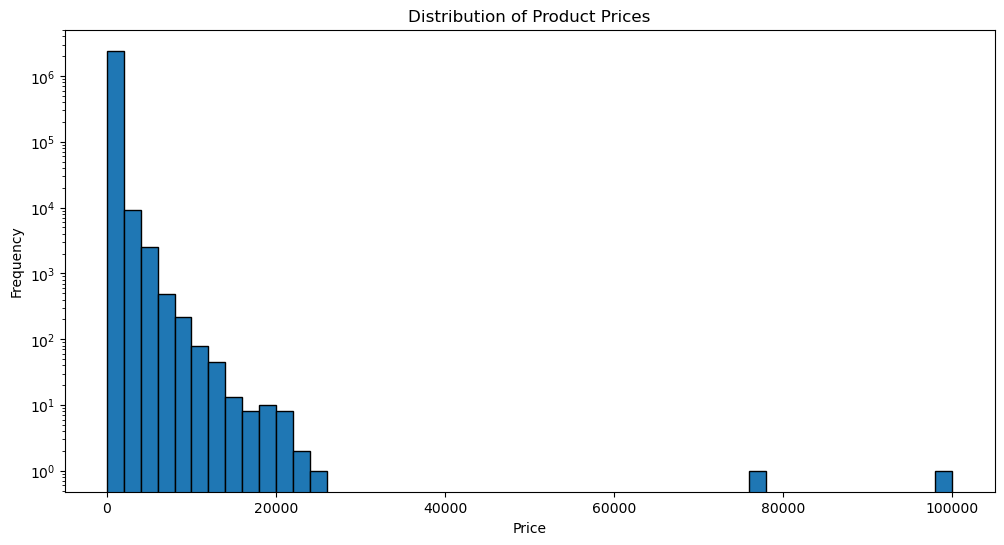

In [56]:
# Plot a histogram of the product prices
plt.figure(figsize=(12, 6))
plt.hist(df['price'], bins=50, edgecolor='black')

plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.yscale('log')  # Using logarithmic scale for better readability
plt.show()


too high prices where the chart cannot handle right way. 
Alternative is range the prices for a common values.
By limiting the x-axis range 100, you can focus on a specific range of prices, which allows for a clearer view of the distribution of the majority of products, excluding extremely high prices 

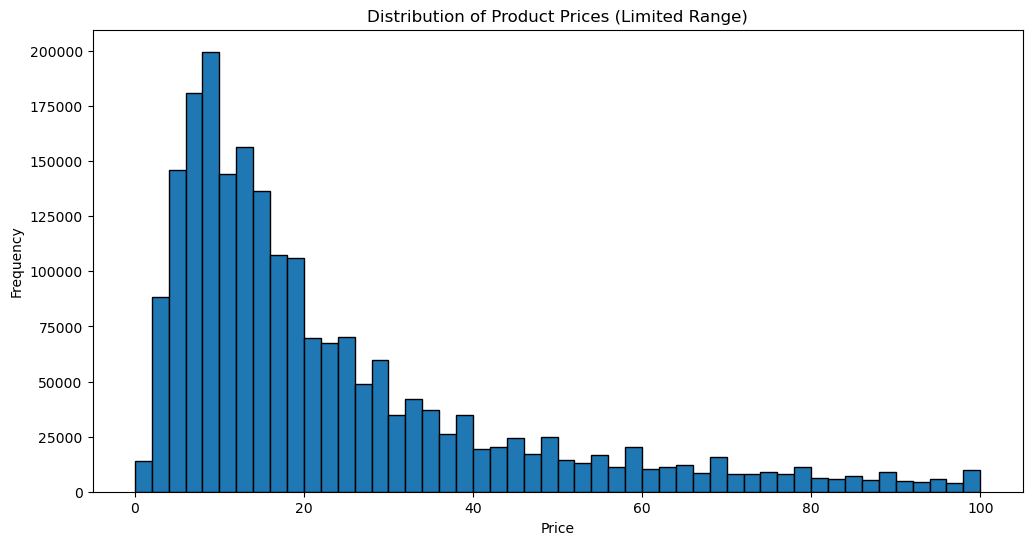

In [60]:
# Plot a histogram of the product prices with limited x-axis range
plt.figure(figsize=(12, 6))
plt.hist(df['price'], bins=50, edgecolor='black', range=(0, 100))  # Adjust the range as needed
plt.title('Distribution of Product Prices (Limited Range)')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()


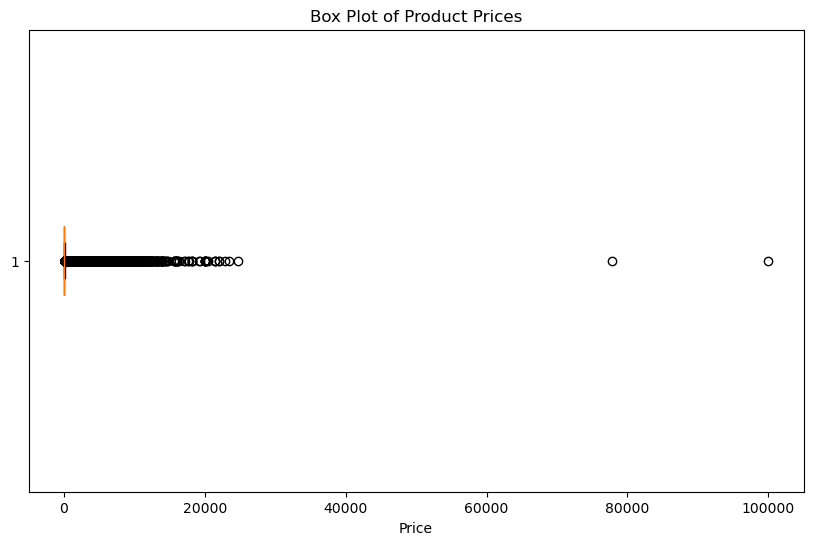

In [53]:
# Plot a box plot of the product prices
plt.figure(figsize=(10, 6))
plt.boxplot(df['price'], vert=False, patch_artist=True)
plt.title('Box Plot of Product Prices')
plt.xlabel('Price')
plt.show()


Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?


Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?


Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?


Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [67]:
# Calculate the mean
mean_stars = df['stars'].mean()

# Calculate the median
median_stars = df['stars'].median()

# Calculate the mode
mode_stars = df['stars'].mode()[0]  # mode() returns a Series, take the first value

print(f"Mean stars: {mean_stars:.2f}")
print(f"Median stars: {median_stars}")
print(f"Mode stars: {mode_stars}")


Mean stars: 2.15
Median stars: 0.0
Mode stars: 0.0


In [68]:

# Calculate variance
variance_stars = df['stars'].var()

# Calculate standard deviation
std_dev_stars= df['stars'].std()

# Calculate range
stars_range = df['stars'].max() - df['stars'].min()

# Calculate interquartile range (IQR)
Q1 = df['stars'].quantile(0.25)
Q3 = df['stars'].quantile(0.75)
IQR = Q3 - Q1

# Print the results
print(f"Variance: {variance_stars:.2f}")
print(f"Standard Deviation: {std_dev_stars:.2f}")
print(f"Range: {stars_range:.2f}")
print(f"Interquartile Range (IQR): {IQR:.2f}")

Variance: 4.82
Standard Deviation: 2.19
Range: 5.00
Interquartile Range (IQR): 4.40


In [71]:
# Calculate the mean
mean_reviews = df['reviews'].mean()

# Calculate the median
median_reviews = df['reviews'].median()

# Calculate the mode
mode_reviews = df['reviews'].mode()[0]  # mode() returns a Series, take the first value

print(f"Mean stars: {mean_reviews:.2f}")
print(f"Median stars: {median_reviews}")
print(f"Mode stars: {mode_reviews}")

# Calculate variance
variance_reviews = df['reviews'].var()

# Calculate standard deviation
std_dev_reviews= df['reviews'].std()

# Calculate range
reviews_range = df['reviews'].max() - df['reviews'].min()

# Calculate interquartile range (IQR)
Q1 = df['reviews'].quantile(0.25)
Q3 = df['reviews'].quantile(0.75)
IQR = Q3 - Q1

# Print the results
print(f"Variance: {variance_reviews:.2f}")
print(f"Standard Deviation: {std_dev_reviews:.2f}")
print(f"Range: {reviews_range:.2f}")
print(f"Interquartile Range (IQR): {IQR:.2f}")

Mean stars: 480.63
Median stars: 0.0
Mode stars: 0
Variance: 35332611.92
Standard Deviation: 5944.12
Range: 1356658.00
Interquartile Range (IQR): 59.00


In [73]:
assimetria = df['stars'].skew()
curtose = df['stars'].kurtosis()

print(f"Assimetria: {assimetria:.2f}")
print(f"Curtose: {curtose:.2f}")

Assimetria: 0.08
Curtose: -1.93


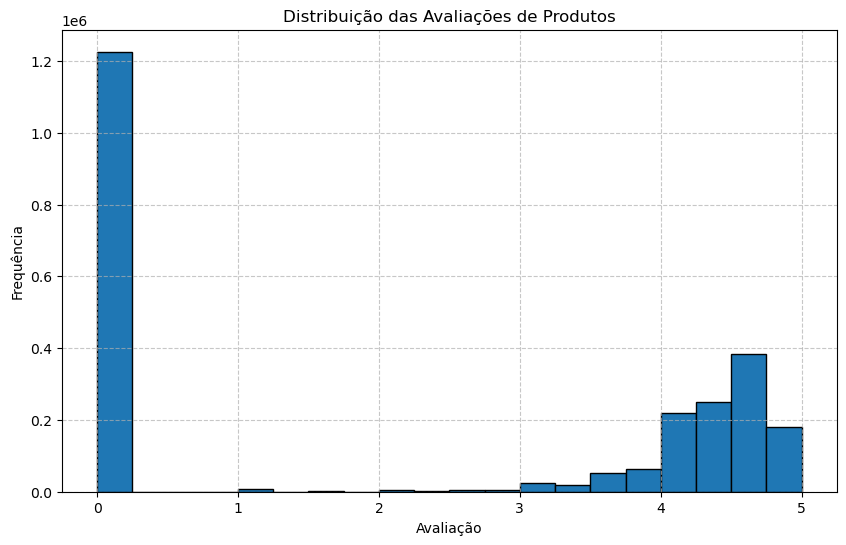

In [74]:
# Plotar o histograma das avaliações de produtos
plt.figure(figsize=(10, 6))
plt.hist(df['stars'], bins=20, edgecolor='black')
plt.title('Distribuição das Avaliações de Produtos')
plt.xlabel('Avaliação')
plt.ylabel('Frequência')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()